# Lab Assessment 4: Bivariate Analysis | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

Dataset: **BEPS**. Base R plots -> `matplotlib`; ggplot2 -> `seaborn`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Load the dataset

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


In [3]:
df = df.dropna().reset_index(drop=True)
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.columns.difference(num_cols).tolist()
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Numerical  : ['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge']
Categorical: ['gender', 'vote']


## 2. Contingency table and stacked bar plots (`vote` vs `gender`)

In [4]:
ct = pd.crosstab(df["vote"], df["gender"])
display(ct)

gender,female,male
vote,,
Conservative,259,203
Labour,372,348
Liberal Democrat,181,162


**(a) Simple stacked bar plot - base style (matplotlib)**

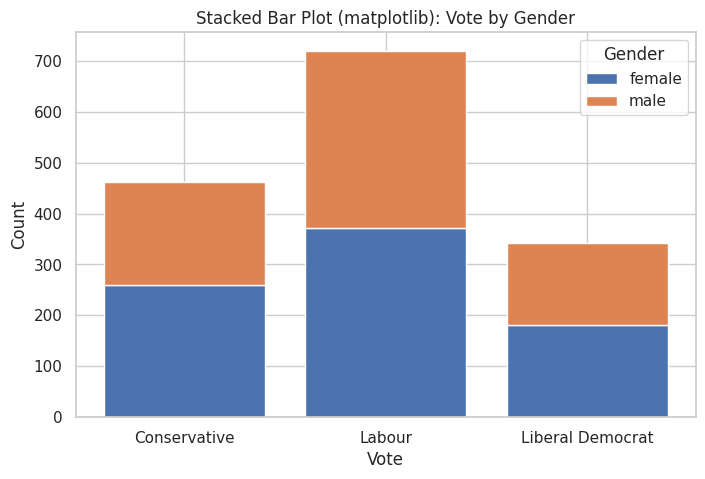

In [5]:
fig, ax = plt.subplots()
bottom = np.zeros(len(ct))
for g in ct.columns:
    ax.bar(ct.index, ct[g], bottom=bottom, label=g)
    bottom += ct[g].values
ax.set_title("Stacked Bar Plot (matplotlib): Vote by Gender")
ax.set_xlabel("Vote")
ax.set_ylabel("Count")
ax.legend(title="Gender")
plt.show()

**(b) Stacked bar plot - ggplot2 style (seaborn)**

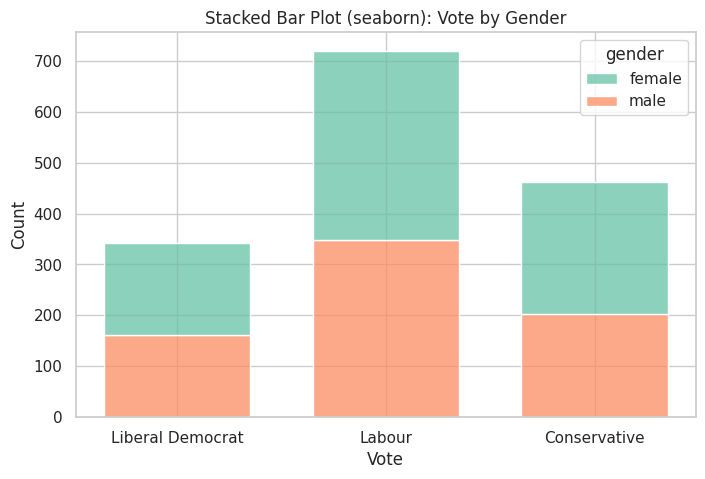

In [6]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="vote", hue="gender", multiple="stack", shrink=0.7, palette="Set2", ax=ax)
ax.set_title("Stacked Bar Plot (seaborn): Vote by Gender")
ax.set_xlabel("Vote")
ax.set_ylabel("Count")
plt.show()

## 3. Grouped / side-by-side bar plot (`vote` vs `economic_cond_national`)

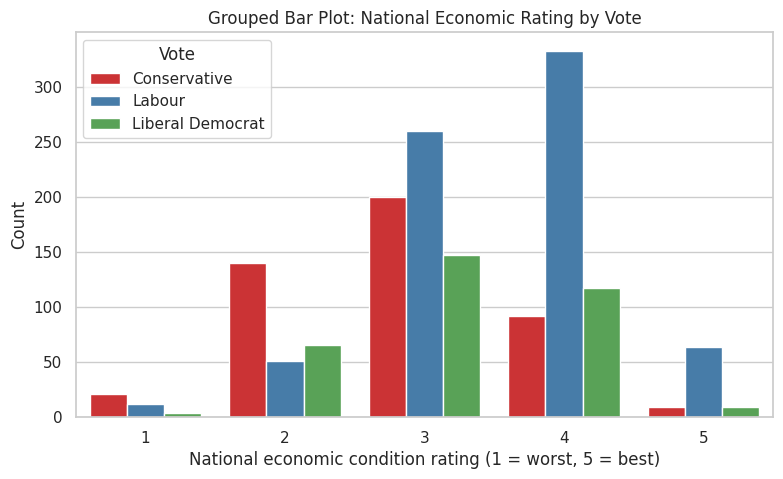

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=df, x="economic_cond_national", hue="vote", palette="Set1", ax=ax)
ax.set_title("Grouped Bar Plot: National Economic Rating by Vote")
ax.set_xlabel("National economic condition rating (1 = worst, 5 = best)")
ax.set_ylabel("Count")
ax.legend(title="Vote")
plt.show()

## 4. Scatter plot of two numerical variables (`Blair` vs `Hague`)
The ratings are whole numbers (1-5), so a small random jitter is added to avoid overplotting.

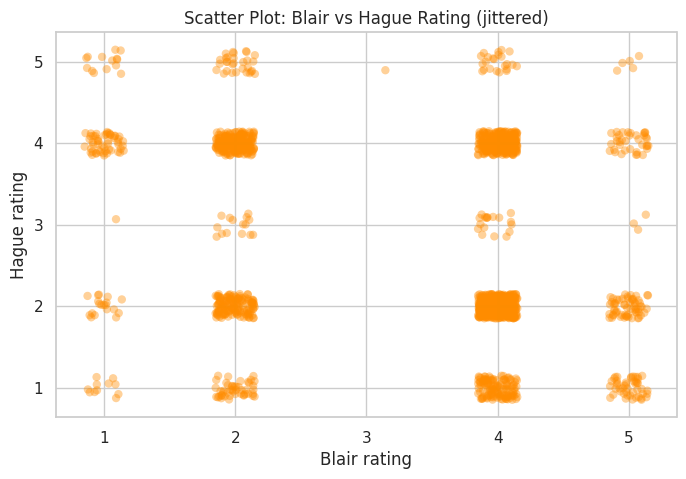

Correlation: -0.243


In [8]:
rng = np.random.default_rng(1)
jx = df["Blair"] + rng.uniform(-0.15, 0.15, len(df))
jy = df["Hague"] + rng.uniform(-0.15, 0.15, len(df))

fig, ax = plt.subplots()
ax.scatter(jx, jy, alpha=0.4, color="darkorange", edgecolor="none")
ax.set_title("Scatter Plot: Blair vs Hague Rating (jittered)")
ax.set_xlabel("Blair rating")
ax.set_ylabel("Hague rating")
plt.show()
print("Correlation:", round(df["Blair"].corr(df["Hague"]), 3))

## 5. Line plot - trend of mean rating with age

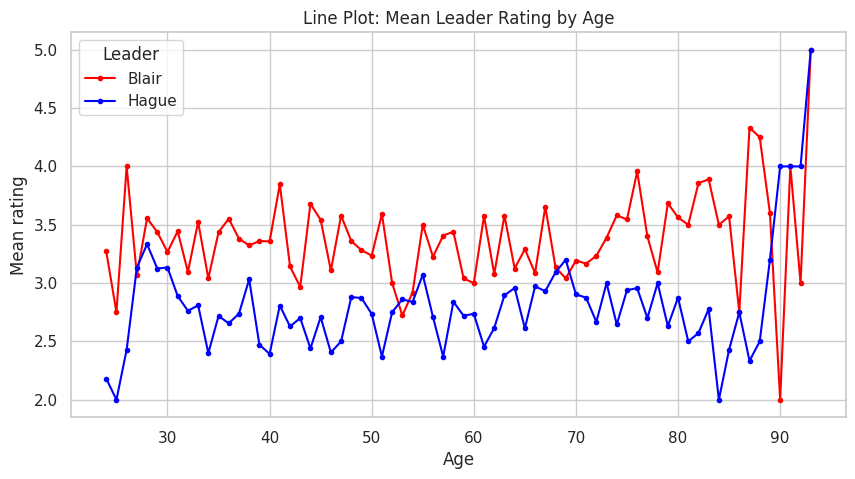

In [9]:
trend = df.groupby("age")[["Blair", "Hague"]].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(trend["age"], trend["Blair"], label="Blair", color="red", marker="o", markersize=3)
ax.plot(trend["age"], trend["Hague"], label="Hague", color="blue", marker="o", markersize=3)
ax.set_title("Line Plot: Mean Leader Rating by Age")
ax.set_xlabel("Age")
ax.set_ylabel("Mean rating")
ax.legend(title="Leader")
plt.show()

## 6. Heatmap of the relationship among numerical variables

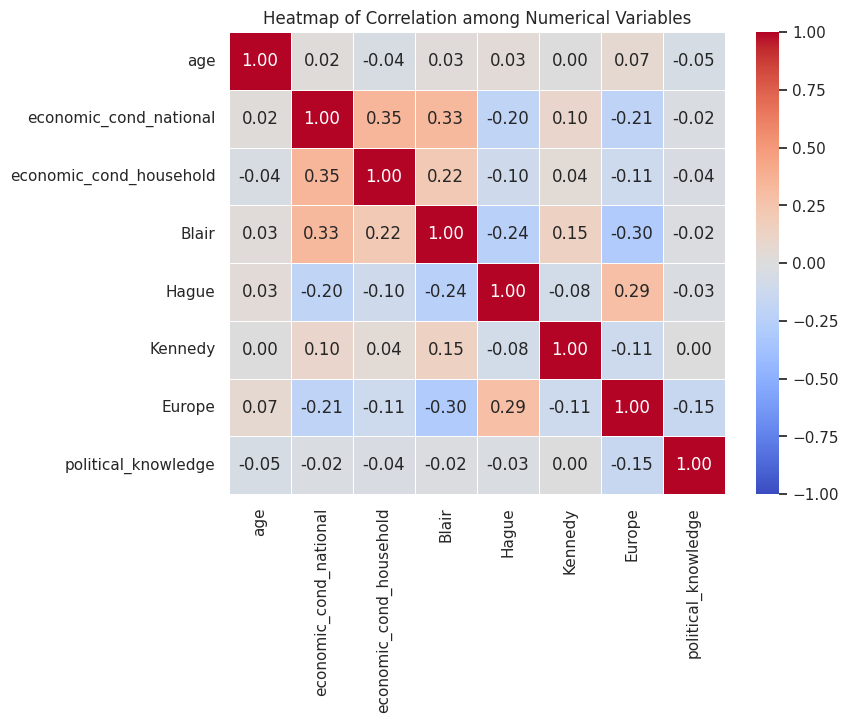

In [10]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Heatmap of Correlation among Numerical Variables")
plt.show()

## 7. Bar chart comparing the values of two variables (mean `Blair` vs mean `Hague` for each party)

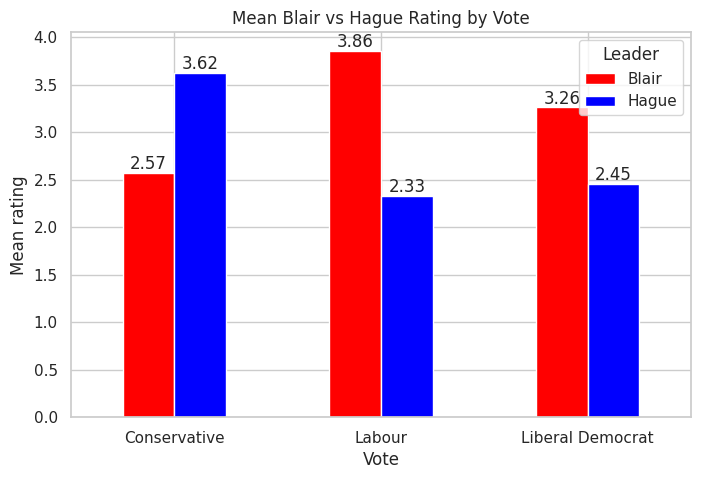

In [11]:
means = df.groupby("vote")[["Blair", "Hague"]].mean()
ax = means.plot(kind="bar", figsize=(8, 5), color=["red", "blue"], rot=0)
ax.set_title("Mean Blair vs Hague Rating by Vote")
ax.set_xlabel("Vote")
ax.set_ylabel("Mean rating")
ax.legend(title="Leader")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f")
plt.show()

## 8. Density plot - numerical (`age`) across categories (`vote`)

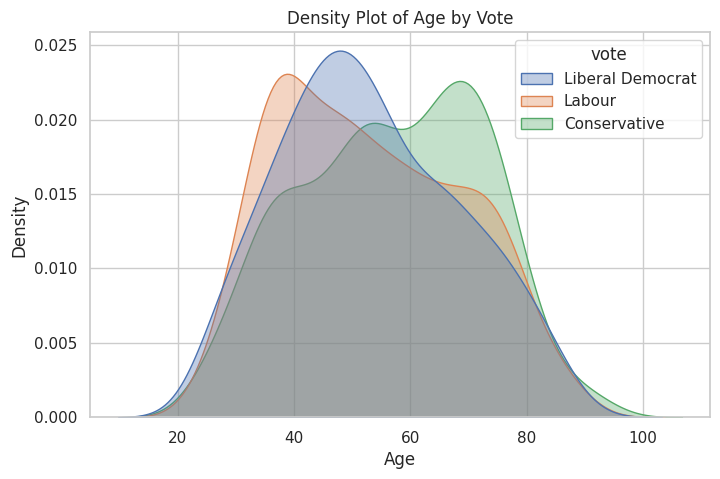

In [12]:
fig, ax = plt.subplots()
sns.kdeplot(data=df, x="age", hue="vote", fill=True, alpha=0.35, common_norm=False, ax=ax)
ax.set_title("Density Plot of Age by Vote")
ax.set_xlabel("Age")
ax.set_ylabel("Density")
plt.show()

## 9. Box plot - `Europe` score across `vote`

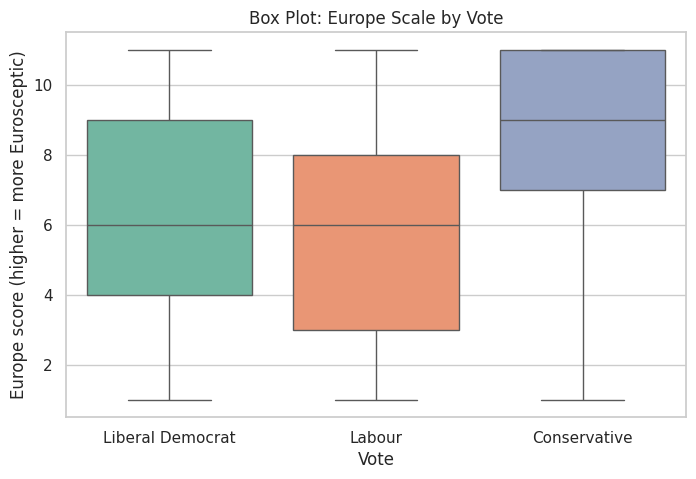

In [13]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="vote", y="Europe", palette="Set2", ax=ax)
ax.set_title("Box Plot: Europe Scale by Vote")
ax.set_xlabel("Vote")
ax.set_ylabel("Europe score (higher = more Eurosceptic)")
plt.show()

## 10. Violin plot - `age` across `vote`

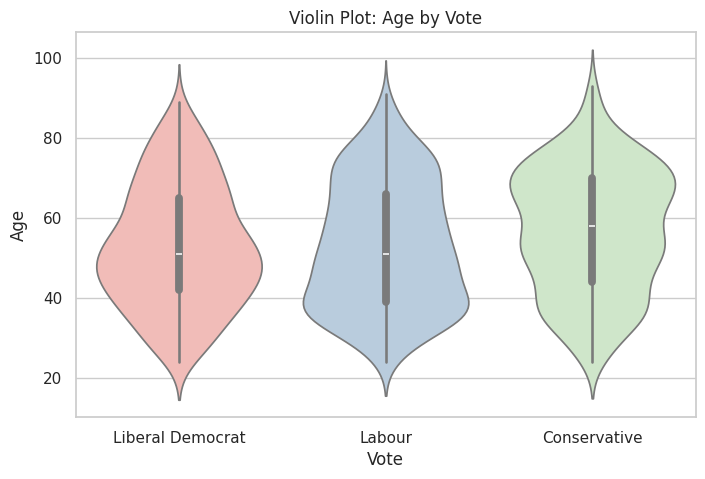

In [14]:
fig, ax = plt.subplots()
sns.violinplot(data=df, x="vote", y="age", palette="Pastel1", ax=ax)
ax.set_title("Violin Plot: Age by Vote")
ax.set_xlabel("Vote")
ax.set_ylabel("Age")
plt.show()

## 11. Violin + box plot combined

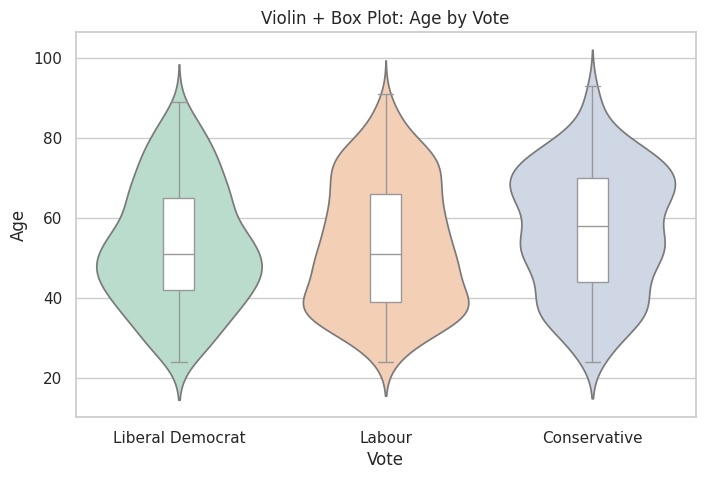

In [15]:
fig, ax = plt.subplots()
sns.violinplot(data=df, x="vote", y="age", inner=None, palette="Pastel2", ax=ax)
sns.boxplot(data=df, x="vote", y="age", width=0.15, boxprops={"zorder": 2}, fliersize=2, ax=ax,
            color="white")
ax.set_title("Violin + Box Plot: Age by Vote")
ax.set_xlabel("Vote")
ax.set_ylabel("Age")
plt.show()

## 12. Correlation matrix and correlogram

,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
age,1.000,0.019,-0.042,0.030,0.035,0.004,0.069,-0.048
economic_cond_national,0.019,1.000,0.346,0.327,-0.200,0.097,-0.209,-0.024
economic_cond_household,-0.042,0.346,1.000,0.215,-0.102,0.040,-0.115,-0.038
Blair,0.030,0.327,0.215,1.000,-0.243,0.148,-0.296,-0.021
Hague,0.035,-0.200,-0.102,-0.243,1.000,-0.080,0.287,-0.030
Kennedy,0.004,0.097,0.040,0.148,-0.080,1.000,-0.110,0.001
Europe,0.069,-0.209,-0.115,-0.296,0.287,-0.110,1.000,-0.152
political_knowledge,-0.048,-0.024,-0.038,-0.021,-0.030,0.001,-0.152,1.000


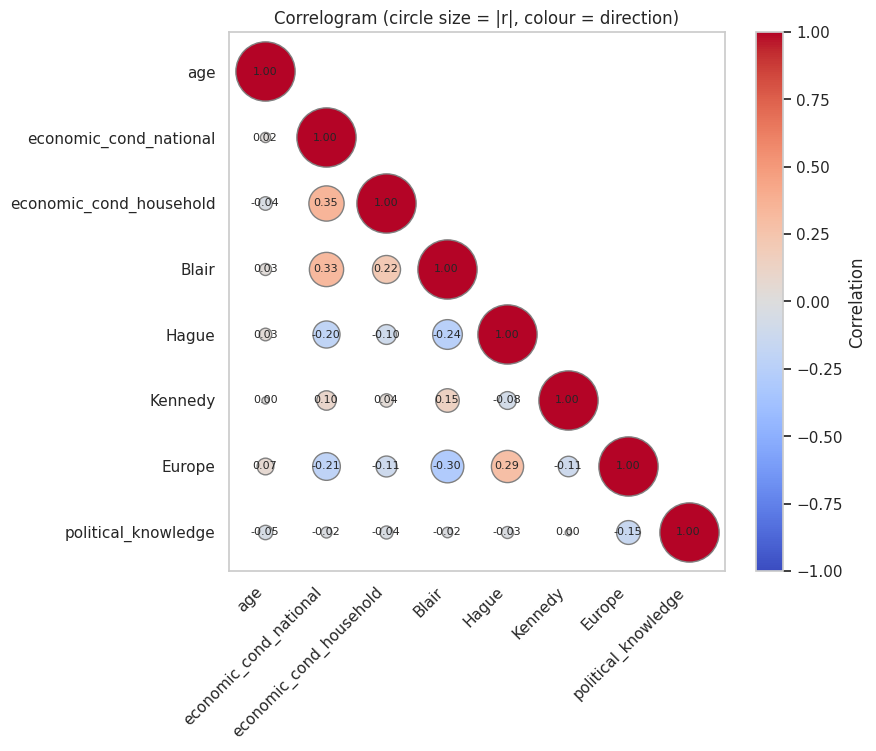

In [16]:
corr = df[num_cols].corr()
display(corr.round(3))

n = len(corr)
fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.get_cmap("coolwarm")
for i in range(n):
    for j in range(n):
        if i >= j:                                    # lower triangle only
            r = corr.iloc[i, j]
            ax.scatter(j, n - 1 - i, s=abs(r) * 1800 + 20, color=cmap((r + 1) / 2), edgecolor="grey")
            ax.text(j, n - 1 - i, f"{r:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(n)); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(corr.columns[::-1])
ax.set_xlim(-0.6, n - 0.4); ax.set_ylim(-0.6, n - 0.4)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-1, 1)); sm.set_array([])
plt.colorbar(sm, ax=ax, label="Correlation")
ax.set_title("Correlogram (circle size = |r|, colour = direction)")
ax.grid(False)
plt.show()